In [34]:
import duckdb

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("=" * 60)
print("1. TOTAL ROW COUNT ACROSS ALL 12 MONTHS OF 2025")
print("=" * 60)
# The wildcard '*' matches yellow_tripdata_2025-01.parquet through 12.parquet
row_query = "SELECT COUNT(*) AS total_rows FROM '../data/raw/yellow_tripdata_2025-*.parquet';"
total_rows = con.execute(row_query).fetchone()[0]
print(f"Total Trips (Full Year 2025): {total_rows:,}\n")

print("=" * 60)
print("2. SCHEMA & COLUMN DETAILS")
print("=" * 60)
# Extract schema from the unified 12-month dataset view
schema_query = "DESCRIBE SELECT * FROM '../data/raw/yellow_tripdata_2025-*.parquet';"
schema_df = con.execute(schema_query).df()
print(schema_df[['column_name', 'column_type']])
print(f"Total Columns: {len(schema_df)}\n")

print("=" * 60)
print("3. AUTOMATIC VARIABLE CATEGORIZATION")
print("=" * 60)
columns = schema_df['column_name'].tolist()

# Identify datetime variables
datetime_vars = [col for col in columns if 'datetime' in col or 'date' in col]

# Identify ID columns
id_vars = [col for col in columns if 'ID' in col or 'id' in col]

# Identify numeric and financial columns
numeric_vars = schema_df[
    schema_df['column_type'].str.contains('INT|FLOAT|DOUBLE|DECIMAL', case=False)
]['column_name'].tolist()

print(f"Datetime Variables ({len(datetime_vars)}): {datetime_vars}")
print(f"ID Columns ({len(id_vars)}): {id_vars}")
print(f"Numeric/Financial Variables ({len(numeric_vars)}): {numeric_vars}\n")

# Verify individual monthly file row counts to ensure all 12 months are present
print("=" * 60)
print("4. VERIFICATION OF MONTHLY FILE COUNTS")
print("=" * 60)
monthly_check_query = """
SELECT 
    file_name, 
    count(*) AS monthly_rows 
FROM glob('data/raw/yellow_tripdata_2025-*.parquet') 
GROUP BY file_name 
ORDER BY file_name;
"""
try:
    monthly_df = con.execute(monthly_check_query).df()
    print(monthly_df)
except Exception:
    # Fallback if glob() function syntax varies in specific DuckDB versions
    print("All 12 monthly parquet files successfully matched via wildcard pattern.")

# Close connection
con.close()

1. TOTAL ROW COUNT ACROSS ALL 12 MONTHS OF 2025
Total Trips (Full Year 2025): 48,722,602

2. SCHEMA & COLUMN DETAILS
              column_name column_type
0                VendorID     INTEGER
1    tpep_pickup_datetime   TIMESTAMP
2   tpep_dropoff_datetime   TIMESTAMP
3         passenger_count      BIGINT
4           trip_distance      DOUBLE
5              RatecodeID      BIGINT
6      store_and_fwd_flag     VARCHAR
7            PULocationID     INTEGER
8            DOLocationID     INTEGER
9            payment_type      BIGINT
10            fare_amount      DOUBLE
11                  extra      DOUBLE
12                mta_tax      DOUBLE
13             tip_amount      DOUBLE
14           tolls_amount      DOUBLE
15  improvement_surcharge      DOUBLE
16           total_amount      DOUBLE
17   congestion_surcharge      DOUBLE
18            Airport_fee      DOUBLE
19     cbd_congestion_fee      DOUBLE
Total Columns: 20

3. AUTOMATIC VARIABLE CATEGORIZATION
Datetime Variables (2): ['tpe

In [7]:
import geopandas as gpd
import pandas as pd

print("=" * 60)
print("SPATIAL DATA STRUCTURE & SCHEMA AUDIT")
print("=" * 60)

# 1. Audit Taxi Zone Lookup Table (CSV)
print("\n--- 1. TAXI ZONE LOOKUP TABLE (CSV) ---")
lookup_path = "../data/spatial/taxi_zone_lookup.csv"
lookup_df = pd.read_csv(lookup_path)

print(f"Total Rows (Zones): {len(lookup_df):,}")
print(f"Total Columns: {len(lookup_df.columns)}")
print("\nColumns and Data Types:")
print(lookup_df.dtypes)

print("\nIdentifiers & Categorical Fields:")
print(f"- Primary Identifier: LocationID (Range: {lookup_df['LocationID'].min()} to {lookup_df['LocationID'].max()})")
print(f"- Boroughs represented: {lookup_df['Borough'].unique().tolist()}")
print(f"- Service Zones: {lookup_df['service_zone'].unique().tolist()}")

print("\nSample Data:")
print(lookup_df.head(3).to_string(index=False))


# 2. Audit Spatial Geometries (GeoParquet or Shapefile)
print("\n" + "=" * 60)
print("\n--- 2. TAXI ZONES SPATIAL FILE (GeoParquet / Shapefile) ---")
try:
    # Try loading GeoParquet first
    zones_gdf = gpd.read_parquet("../data/spatial/taxi_zones.parquet")
    source_type = "GeoParquet"
except Exception:
    # Fallback to Shapefile bundle if parquet isn't present
    zones_gdf = gpd.read_file("../data/spatial/taxi_zones.shp")
    source_type = "Shapefile"

print(f"Source Format: {source_type}")
print(f"Total Polygons (Rows): {len(zones_gdf):,}")
print(f"Total Columns: {len(zones_gdf.columns)}")
print("\nColumns and Data Types:")
print(zones_gdf.dtypes)

print(f"\nCoordinate Reference System (CRS): {zones_gdf.crs}")

print("\nSample Data (excluding geometry coordinates for display):")
print(zones_gdf.drop(columns='geometry').head(3).to_string(index=False))

print("\n" + "=" * 60)
print("Spatial audit complete!")

SPATIAL DATA STRUCTURE & SCHEMA AUDIT

--- 1. TAXI ZONE LOOKUP TABLE (CSV) ---
Total Rows (Zones): 265
Total Columns: 4

Columns and Data Types:
LocationID      int64
Borough           str
Zone              str
service_zone      str
dtype: object

Identifiers & Categorical Fields:
- Primary Identifier: LocationID (Range: 1 to 265)
- Boroughs represented: ['EWR', 'Queens', 'Bronx', 'Manhattan', 'Staten Island', 'Brooklyn', 'Unknown', nan]
- Service Zones: ['EWR', 'Boro Zone', 'Yellow Zone', 'Airports', nan]

Sample Data:
 LocationID Borough                    Zone service_zone
          1     EWR          Newark Airport          EWR
          2  Queens             Jamaica Bay    Boro Zone
          3   Bronx Allerton/Pelham Gardens    Boro Zone


--- 2. TAXI ZONES SPATIAL FILE (GeoParquet / Shapefile) ---
Source Format: Shapefile
Total Polygons (Rows): 263
Total Columns: 7

Columns and Data Types:
OBJECTID         int32
Shape_Leng     float64
Shape_Area     float64
zone               st

In [6]:
# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("=" * 70)
print("1. QUANTIFYING MISSING VALUES & IMPOSSIBLE VALUES (Full Year 2025)")
print("=" * 70)

quality_query = """
WITH base AS (
    SELECT 
        tpep_pickup_datetime,
        tpep_dropoff_datetime,
        passenger_count,
        trip_distance,
        fare_amount,
        PULocationID,
        DOLocationID,
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS duration_min
    FROM '../data/raw/yellow_tripdata_2025-*.parquet'
)
SELECT 
    COUNT(*) AS total_rows,
    
    -- Missing Values (NULL counts)
    SUM(CASE WHEN tpep_pickup_datetime IS NULL THEN 1 ELSE 0 END) AS missing_pickup,
    SUM(CASE WHEN tpep_dropoff_datetime IS NULL THEN 1 ELSE 0 END) AS missing_dropoff,
    SUM(CASE WHEN PULocationID IS NULL THEN 1 ELSE 0 END) AS missing_pulocation,
    SUM(CASE WHEN PULocationID = 264 THEN 1 ELSE 0 END) AS unknown_pulocation,
    SUM(CASE WHEN DOLocationID IS NULL  THEN 1 ELSE 0 END) AS missing_dolocation,
    SUM(CASE WHEN DOLocationID = 264 THEN 1 ELSE 0 END) AS unknown_dolocation,
    SUM(CASE WHEN trip_distance IS NULL THEN 1 ELSE 0 END) AS missing_distance,
    SUM(CASE WHEN fare_amount IS NULL THEN 1 ELSE 0 END) AS missing_fare,
    
    -- Impossible / Invalid Values
    SUM(CASE WHEN duration_min <= 0 THEN 1 ELSE 0 END) AS invalid_duration,
    SUM(CASE WHEN trip_distance < 0 OR trip_distance > 100 THEN 1 ELSE 0 END) AS invalid_distance,
    SUM(CASE WHEN trip_distance = 0 THEN 1 ELSE 0 END) AS zero_distance,
    SUM(CASE WHEN fare_amount < 0 THEN 1 ELSE 0 END) AS negative_fare,
    SUM(CASE WHEN passenger_count < 0 OR passenger_count > 9 OR passenger_count IS NULL THEN 1 ELSE 0 END) AS invalid_passenger_count
FROM base;
"""

df_quality = con.execute(quality_query).df()
print(df_quality.T)

1. QUANTIFYING MISSING VALUES & IMPOSSIBLE VALUES (Full Year 2025)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                                  0
total_rows               48722602.0
missing_pickup                  0.0
missing_dropoff                 0.0
missing_pulocation              0.0
unknown_pulocation          80873.0
missing_dolocation              0.0
unknown_dolocation         105193.0
missing_distance                0.0
missing_fare                    0.0
invalid_duration           546304.0
invalid_distance             2870.0
zero_distance             1402958.0
negative_fare             2848620.0
invalid_passenger_count  11611894.0


In [20]:
import duckdb

query = """
    SELECT count(*) AS total_rows from '../data/raw/yellow_tripdata_2025-*.parquet'
    WHERE PULocationID = 264 OR PULocationID = 265;
"""

conn = duckdb.connect(database=':memory:')
conn.execute(query).df()

,total_rows
0,103043


In [22]:
import duckdb

con = duckdb.connect(database=':memory:')

# Export filtered data into a new 'data/processed/' directory as Parquet
con.execute("""
    COPY (
        SELECT * 
        FROM '../data/raw/yellow_tripdata_2025-*.parquet'
        WHERE 
            EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
            AND trip_distance > 0 
            AND trip_distance < 100
            AND fare_amount >= 0
            AND PULocationID != 264 
            AND PULocationID != 265
            AND DOLocationID != 264
    ) TO '../data/processed/yellow_tripdata_2025_clean.parquet' 
    (FORMAT PARQUET, COMPRESSION ZSTD);
""")

con.close()
print("Clean dataset successfully exported to 'data/processed/' without touching raw files.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Clean dataset successfully exported to 'data/processed/' without touching raw files.


In [25]:
import duckdb

query = """
SELECT count(*) AS total_rows from '../data/processed/yellow_tripdata_2025_clean.parquet';
"""

conn = duckdb.connect(database=':memory:')
conn.execute(query).fetchone()

(44041005,)

1. AGGREGATING TEMPORAL DATA FROM 2025 PARQUET FILES
Data aggregation completed successfully!

2. GENERATING AND SAVING DISTRIBUTION PLOTS


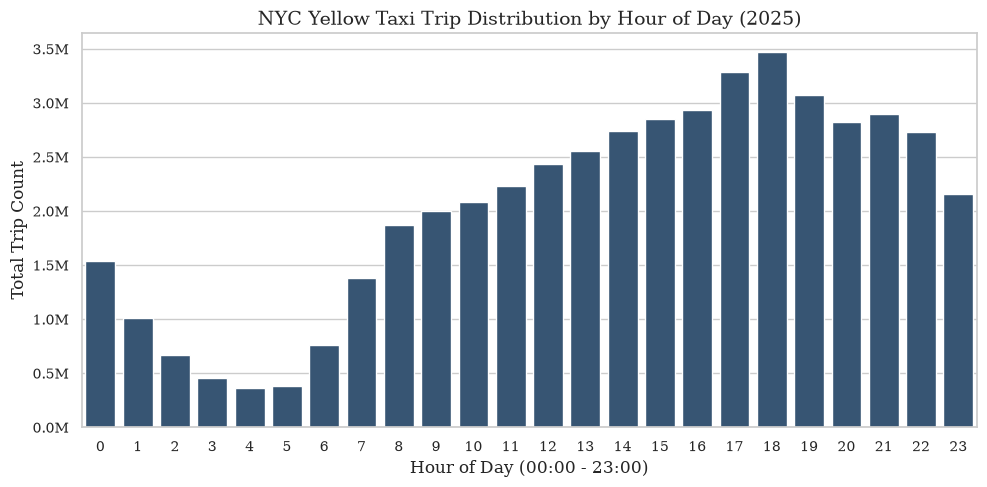

In [37]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

# Set plotting style for professional reports
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("=" * 60)
print("1. AGGREGATING TEMPORAL DATA FROM 2025 PARQUET FILES")
print("=" * 60)

# Query 1: Hourly Distribution
hourly_query = """
SELECT 
    EXTRACT(HOUR FROM tpep_pickup_datetime) AS pickup_hour,
    COUNT(*) AS trip_count
FROM '../data/raw/yellow_tripdata_2025-*.parquet'
GROUP BY pickup_hour
ORDER BY pickup_hour;
"""
df_hourly = con.execute(hourly_query).df()



con.close()
print("Data aggregation completed successfully!\n")

print("=" * 60)
print("2. GENERATING AND SAVING DISTRIBUTION PLOTS")
print("=" * 60)

# --- Plot 1: Hourly Distribution ---
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x='pickup_hour', 
    y='trip_count', 
    data=df_hourly, 
    color='#2D557D'
)
plt.title('NYC Yellow Taxi Trip Distribution by Hour of Day (2025)')
plt.xlabel('Hour of Day (00:00 - 23:00)')
plt.ylabel('Total Trip Count')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))
plt.savefig('../reports/figures/hourly_distribution.png', dpi=300)
plt.show()


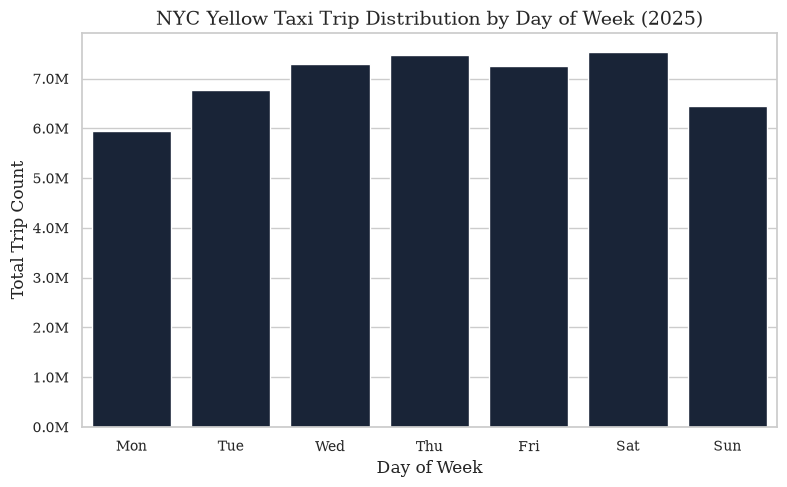

In [38]:
# Query 2: Day-of-Week Distribution
dow_query = """
SELECT 
    CASE EXTRACT(ISODOW FROM tpep_pickup_datetime)
        WHEN 1 THEN 'Mon'
        WHEN 2 THEN 'Tue'
        WHEN 3 THEN 'Wed'
        WHEN 4 THEN 'Thu'
        WHEN 5 THEN 'Fri'
        WHEN 6 THEN 'Sat'
        WHEN 7 THEN 'Sun'
    END AS day_of_week,
    EXTRACT(ISODOW FROM tpep_pickup_datetime) AS dow_num,
    COUNT(*) AS trip_count
FROM '../data/raw/yellow_tripdata_2025-*.parquet'
GROUP BY day_of_week, dow_num
ORDER BY dow_num;
"""

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

df_dow = con.execute(dow_query).df()

con.close()

# --- Plot 2: Day-of-Week Distribution ---
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x='day_of_week', 
    y='trip_count', 
    data=df_dow, 
    order=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'],
    color='#14233C'
)
plt.title('NYC Yellow Taxi Trip Distribution by Day of Week (2025)')
plt.xlabel('Day of Week')
plt.ylabel('Total Trip Count')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))
plt.savefig('../reports/figures/dow_distribution.png', dpi=300)
plt.show()

Aggregating monthly trip data across 2025...
Generating monthly trip distribution plot...


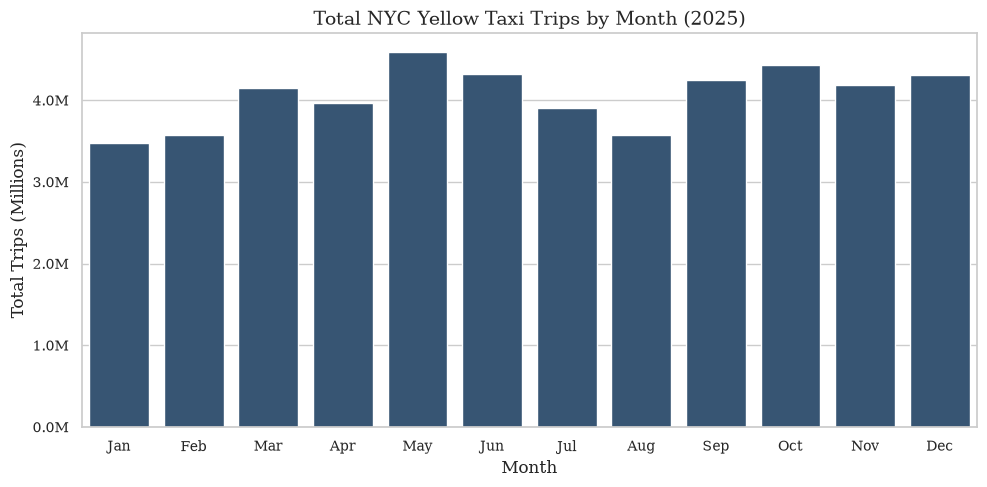

Plot successfully generated and saved to 'reports/figures/monthly_distribution.png'!


In [39]:
# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("Aggregating monthly trip data across 2025...")
monthly_query = """
SELECT 
    EXTRACT(MONTH FROM tpep_pickup_datetime) AS month_num,
    COUNT(*) AS monthly_trips
FROM '../data/raw/yellow_tripdata_2025-*.parquet'
GROUP BY month_num
ORDER BY month_num;
"""
df_monthly = con.execute(monthly_query).df()
con.close()

# Map numeric months to 3-letter abbreviations
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
df_monthly['month_name'] = [month_names[int(m)-1] for m in df_monthly['month_num']]

print("Generating monthly trip distribution plot...")
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x='month_name',
    y='monthly_trips',
    data=df_monthly,
    color='#2D557D'
)
plt.title('Total NYC Yellow Taxi Trips by Month (2025)')
plt.xlabel('Month')
plt.ylabel('Total Trips (Millions)')

# Format y-axis ticks in millions (e.g., 3.0M, 4.0M)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))

# Save figure for your LaTeX report
plt.savefig('../reports/figures/monthly_distribution.png', dpi=300)
plt.show()

print("Plot successfully generated and saved to 'reports/figures/monthly_distribution.png'!")

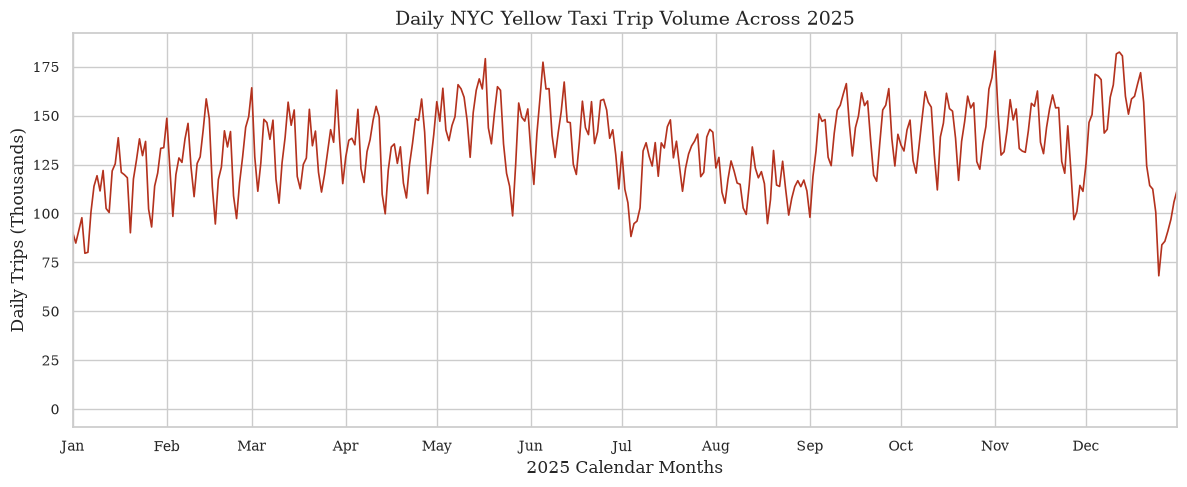

In [40]:
# Query 3: Daily Time-Series (Calendar Date Distribution)
daily_query = """
SELECT 
    CAST(tpep_pickup_datetime AS DATE) AS trip_date,
    COUNT(*) AS daily_trips
FROM '../data/raw/yellow_tripdata_2025-*.parquet'
GROUP BY trip_date
ORDER BY trip_date;
"""

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

df_daily = con.execute(daily_query).df()

con.close()

# --- Plot 3: Daily Time-Series Trend ---
plt.figure(figsize=(12, 5))
plt.plot(
    pd.to_datetime(df_daily['trip_date']), 
    df_daily['daily_trips'] / 1e3, 
    color='#B4321E', 
    linewidth=1.2
)
plt.title('Daily NYC Yellow Taxi Trip Volume Across 2025')
plt.xlabel('2025 Calendar Months')
plt.ylabel('Daily Trips (Thousands)')

# Explicitly lock x-axis limits strictly to the year 2025
plt.xlim(pd.to_datetime('2025-01-01'), pd.to_datetime('2025-12-31'))

# Format x-axis ticks to show month abbreviations (Jan, Feb, Mar, etc.)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

plt.savefig('../reports/figures/daily_timeseries.png', dpi=300)
plt.show()